In [1]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.13.15 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 17:17:48) [MSC v.1942 64 bit (AMD64)]


In [2]:
import numpy
import pandas
import matplotlib
import PIL

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow:", PIL.__version__)

NumPy: 2.2.5
Pandas: 2.2.3
Matplotlib: 3.10.3
Pillow: 11.2.1


In [3]:
import sys

print(sys.executable)

C:\Users\rajva\anaconda3\envs\image_captioning\python.exe


In [4]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch version: 2.13.0+cpu
Torchvision version: 0.28.0+cpu
CUDA available: False
Using CPU


In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Project paths
PROJECT_DIR = r"C:\Users\rajva\Desktop\image-captioning Project"
IMAGE_DIR = os.path.join(PROJECT_DIR, "data", "raw", "Images")
CAPTION_FILE = os.path.join(PROJECT_DIR, "data", "raw", "captions.txt")

print("Project directory:", PROJECT_DIR)
print("Image directory:", IMAGE_DIR)
print("Caption file:", CAPTION_FILE)

Project directory: C:\Users\rajva\Desktop\image-captioning Project
Image directory: C:\Users\rajva\Desktop\image-captioning Project\data\raw\Images
Caption file: C:\Users\rajva\Desktop\image-captioning Project\data\raw\captions.txt


In [8]:
# Read captions file
with open(CAPTION_FILE, "r", encoding="utf-8") as file:
    caption_lines = file.readlines()

print("Total caption lines:", len(caption_lines))
print("\nFirst 5 captions:\n")

for line in caption_lines[:5]:
    print(line.strip())

Total caption lines: 40460

First 5 captions:

1000268201_693b08cb0e.jpg#0	A child in a pink dress is climbing up a set of stairs in an entry way .
1000268201_693b08cb0e.jpg#1	A girl going into a wooden building .
1000268201_693b08cb0e.jpg#2	A little girl climbing into a wooden playhouse .
1000268201_693b08cb0e.jpg#3	A little girl climbing the stairs to her playhouse .
1000268201_693b08cb0e.jpg#4	A little girl in a pink dress going into a wooden cabin .


In [9]:
# Get all image filenames
image_files = [
    file for file in os.listdir(IMAGE_DIR)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images:", len(image_files))
print("\nFirst 10 image filenames:")

for image in image_files[:10]:
    print(image)
    

Total images: 8091

First 10 image filenames:
1000268201_693b08cb0e.jpg
1001773457_577c3a7d70.jpg
1002674143_1b742ab4b8.jpg
1003163366_44323f5815.jpg
1007129816_e794419615.jpg
1007320043_627395c3d8.jpg
1009434119_febe49276a.jpg
1012212859_01547e3f17.jpg
1015118661_980735411b.jpg
1015584366_dfcec3c85a.jpg


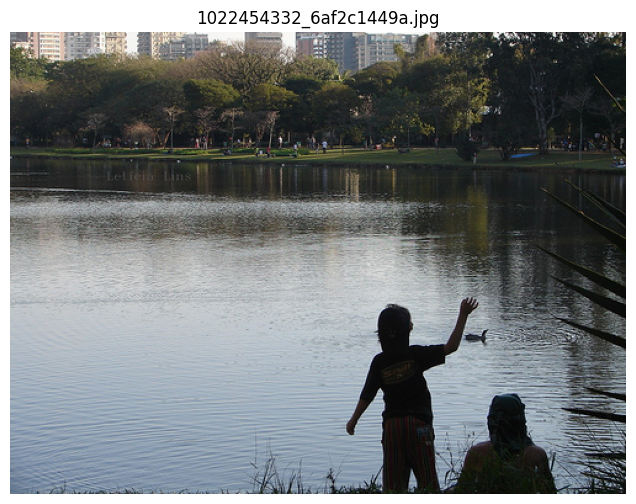

Captions for this image:

child and a woman are at waters edge in a big city .
large lake with a lone duck swimming in it with several people around the edge of it .
little boy at a lake watching a duck .
young boy waves his hand at the duck in the water surrounded by a green park .
people are at the edge of a lake , facing the water and the city skyline .


In [10]:
# Select the first image
image_name = image_files[16]

# Build the complete image path
image_path = os.path.join(IMAGE_DIR, image_name)

# Open and display the image
image = Image.open(image_path)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(image_name)
plt.show()

# Find all captions belonging to this image
print("Captions for this image:\n")

for line in caption_lines:
    if line.startswith(image_name + "#"):
        print(line.strip().split(" ", 1)[1])

In [11]:
from collections import Counter

# Extract image names from caption file
caption_image_names = []

for line in caption_lines:
    image_name = line.split("#")[0]
    caption_image_names.append(image_name)

# Count captions for each image
caption_count = Counter(caption_image_names)

print("Total caption records:", len(caption_lines))
print("Unique images in captions:", len(caption_count))

print("\nCaption count per image:")
print("Minimum:", min(caption_count.values()))
print("Maximum:", max(caption_count.values()))

print("\nNumber of images with exactly 5 captions:",
      sum(1 for count in caption_count.values() if count == 5))

Total caption records: 40460
Unique images in captions: 8092

Caption count per image:
Minimum: 5
Maximum: 5

Number of images with exactly 5 captions: 8092


In [12]:
# Paths to the official Flickr8k split files

TRAIN_FILE = os.path.join(
    PROJECT_DIR,
    "data",
    "raw",
    "Flickr_8k.trainImages.txt"
)

DEV_FILE = os.path.join(
    PROJECT_DIR,
    "data",
    "raw",
    "Flickr_8k.devImages.txt"
)

TEST_FILE = os.path.join(
    PROJECT_DIR,
    "data",
    "raw",
    "Flickr_8k.testImages.txt"
)

# Read the files
with open(TRAIN_FILE, "r", encoding="utf-8") as file:
    train_images = [line.strip() for line in file if line.strip()]

with open(DEV_FILE, "r", encoding="utf-8") as file:
    dev_images = [line.strip() for line in file if line.strip()]

with open(TEST_FILE, "r", encoding="utf-8") as file:
    test_images = [line.strip() for line in file if line.strip()]

print("Training images:", len(train_images))
print("Validation/Dev images:", len(dev_images))
print("Test images:", len(test_images))

print("\nTotal split images:",
      len(train_images) + len(dev_images) + len(test_images))

Training images: 6000
Validation/Dev images: 1000
Test images: 1000

Total split images: 8000


In [13]:
# Create sets for comparison

all_caption_images = set(caption_count.keys())

official_split_images = set(train_images) | set(dev_images) | set(test_images)

# Find images present in captions but absent from official splits
extra_images = all_caption_images - official_split_images

print("Total captioned images:", len(all_caption_images))
print("Official split images:", len(official_split_images))
print("Images outside official splits:", len(extra_images))

print("\nFirst 20 extra images:")
for image in sorted(extra_images)[:20]:
    print(image)

Total captioned images: 8092
Official split images: 8000
Images outside official splits: 92

First 20 extra images:
1155138244_859fd6e079.jpg
1468103286_96a6e07029.jpg
1479857177_9d4a6f38fd.jpg
1643915227_9f48068772.jpg
1797554350_20998753c0.jpg
1808504612_3508f3c9bb.jpg
199463720_329a802206.jpg
2058091220_2087270068.jpg
2087317114_cf06df5aa5.jpg
2136455112_202c093ba4.jpg
2221818690_9003756d33.jpg
2258277193_586949ec62.jpg.1
2319197581_94f807b204.jpg
236095031_5cb17dc54a.jpg
2394824046_51cec8e5e7.jpg
240696675_7d05193aa0.jpg
2410153942_ba4a136358.jpg
2428275562_4bde2bc5ea.jpg
2553619107_d382a820f9.jpg
2557972410_6925fe695c.jpg


In [14]:
# Create sets for fast lookup

train_set = set(train_images)
val_set = set(dev_images)
test_set = set(test_images)

print("Training set:", len(train_set))
print("Validation set:", len(val_set))
print("Test set:", len(test_set))

# Check that there is no overlap between the splits

print("\nTrain ∩ Validation:",
      len(train_set.intersection(val_set)))

print("Train ∩ Test:",
      len(train_set.intersection(test_set)))

print("Validation ∩ Test:",
      len(val_set.intersection(test_set))) 

Training set: 6000
Validation set: 1000
Test set: 1000

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [15]:
# Find lines that do not contain a caption after the image ID

bad_lines = []

for i, line in enumerate(caption_lines):
    line = line.strip()

    if not line:
        bad_lines.append((i + 1, "EMPTY LINE"))
        continue

    parts = line.split(" ", 1)

    if len(parts) != 2:
        bad_lines.append((i + 1, line))

print("Number of problematic lines:", len(bad_lines))

print("\nProblematic lines:")
for line_number, content in bad_lines[:20]:
    print(f"Line {line_number}: {content!r}")

Number of problematic lines: 2

Problematic lines:
Line 9311: '2428275562_4bde2bc5ea.jpg#0\tA'
Line 33366: '3640443200_b8066f37f6.jpg#0\ta'


In [16]:
# Create structured caption data

data = []

for line in caption_lines:
    line = line.strip()

    # Skip empty lines
    if not line:
        continue

    # Split using any whitespace (space or tab)
    parts = line.split(None, 1)

    # Skip malformed lines that still do not contain a caption
    if len(parts) != 2:
        continue

    image_id, caption = parts

    # Remove #0, #1, #2, #3, #4
    image_name = image_id.split("#")[0]

    # Assign the official dataset split
    if image_name in train_set:
        split = "train"

    elif image_name in val_set:
        split = "validation"

    elif image_name in test_set:
        split = "test"

    else:
        # Ignore images outside the official 8000-image split
        continue

    data.append({
        "image": image_name,
        "caption": caption.strip(),
        "split": split
    })

# Convert to DataFrame
df = pd.DataFrame(data)

print("Total records:", len(df))

print("\nRecords by split:")
print(df["split"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Total records: 40000

Records by split:
split
train         30000
validation     5000
test           5000
Name: count, dtype: int64

First 5 rows:


,image,caption,split
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...,train
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .,train
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .,train
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...,train
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...,train


## Caption Preprocessing

In [17]:
# Display some captions before preprocessing

print("Sample captions before preprocessing:\n")

for caption in df["caption"].head(10):
    print(caption)

Sample captions before preprocessing:

A child in a pink dress is climbing up a set of stairs in an entry way .
A girl going into a wooden building .
A little girl climbing into a wooden playhouse .
A little girl climbing the stairs to her playhouse .
A little girl in a pink dress going into a wooden cabin .
A black dog and a spotted dog are fighting
A black dog and a tri-colored dog playing with each other on the road .
A black dog and a white dog with brown spots are staring at each other in the street .
Two dogs of different breeds looking at each other on the road .
Two dogs on pavement moving toward each other .


In [18]:
import re
import pandas as pd
import numpy as np
def normalize_caption(caption):
    # Convert to lowercase
    caption = caption.lower()

    # Removing  extra spaces
    caption = re.sub(r"\s+", " ", caption).strip()

    # Remove spaces before punctuation
    caption = re.sub(r"\s+([.,!?;:])", r"\1", caption)

    return caption

# Apply normalization
df["clean_caption"] = df["caption"].apply(normalize_caption)

# Show original vs cleaned captions
print("Original vs cleaned captions:\n")

for i in range(5):
    print("Original:", df.iloc[i]["caption"])
    print("Cleaned :", df.iloc[i]["clean_caption"])
    print()

Original vs cleaned captions:

Original: A child in a pink dress is climbing up a set of stairs in an entry way .
Cleaned : a child in a pink dress is climbing up a set of stairs in an entry way.

Original: A girl going into a wooden building .
Cleaned : a girl going into a wooden building.

Original: A little girl climbing into a wooden playhouse .
Cleaned : a little girl climbing into a wooden playhouse.

Original: A little girl climbing the stairs to her playhouse .
Cleaned : a little girl climbing the stairs to her playhouse.

Original: A little girl in a pink dress going into a wooden cabin .
Cleaned : a little girl in a pink dress going into a wooden cabin.



In [19]:
def tokenize_caption(caption):
    return caption.split()

df["tokens"] = df["clean_caption"].apply(tokenize_caption)

print("Tokenization examples:\n")

for i in range(5):
    print("Caption:", df.iloc[i]["clean_caption"])
    print("Tokens  :", df.iloc[i]["tokens"])
    print()

Tokenization examples:

Caption: a child in a pink dress is climbing up a set of stairs in an entry way.
Tokens  : ['a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', 'entry', 'way.']

Caption: a girl going into a wooden building.
Tokens  : ['a', 'girl', 'going', 'into', 'a', 'wooden', 'building.']

Caption: a little girl climbing into a wooden playhouse.
Tokens  : ['a', 'little', 'girl', 'climbing', 'into', 'a', 'wooden', 'playhouse.']

Caption: a little girl climbing the stairs to her playhouse.
Tokens  : ['a', 'little', 'girl', 'climbing', 'the', 'stairs', 'to', 'her', 'playhouse.']

Caption: a little girl in a pink dress going into a wooden cabin.
Tokens  : ['a', 'little', 'girl', 'in', 'a', 'pink', 'dress', 'going', 'into', 'a', 'wooden', 'cabin.']



In [20]:
START_TOKEN = "<START>"
END_TOKEN = "<END>"

def add_special_tokens(tokens):
    return [START_TOKEN] + tokens + [END_TOKEN]

df["tokens_with_special"] = df["tokens"].apply(add_special_tokens)

print("Captions with special tokens:\n")

for i in range(5):
    print(df.iloc[i]["tokens_with_special"])
    print()

Captions with special tokens:

['<START>', 'a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', 'entry', 'way.', '<END>']

['<START>', 'a', 'girl', 'going', 'into', 'a', 'wooden', 'building.', '<END>']

['<START>', 'a', 'little', 'girl', 'climbing', 'into', 'a', 'wooden', 'playhouse.', '<END>']

['<START>', 'a', 'little', 'girl', 'climbing', 'the', 'stairs', 'to', 'her', 'playhouse.', '<END>']

['<START>', 'a', 'little', 'girl', 'in', 'a', 'pink', 'dress', 'going', 'into', 'a', 'wooden', 'cabin.', '<END>']



## limit

In [21]:
from collections import Counter

# Count how many times each token appears
token_counter = Counter()

for tokens in df["tokens_with_special"]:
    token_counter.update(tokens)

# Create vocabulary
special_tokens = ["<PAD>", "<START>", "<END>", "<UNK>"]

vocab = special_tokens + sorted(
    token for token in token_counter
    if token not in special_tokens
)

# Create word-to-ID mapping
word_to_id = {word: idx for idx, word in enumerate(vocab)}

# Create ID-to-word mapping
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Vocabulary size:", len(vocab))

print("\nFirst 20 vocabulary tokens:")
for word in vocab[:20]:
    print(word, "->", word_to_id[word])

Vocabulary size: 12076

First 20 vocabulary tokens:
<PAD> -> 0
<START> -> 1
<END> -> 2
<UNK> -> 3
" -> 4
". -> 5
"? -> 6
# -> 7
& -> 8
' -> 9
'. -> 10
'n' -> 11
's -> 12
's-eye-view -> 13
's. -> 14
'slide. -> 15
( -> 16
) -> 17
- -> 18
-ependent -> 19


In [22]:
# Convert each token into its corresponding ID

df["token_ids"] = df["tokens_with_special"].apply(
    lambda tokens: [word_to_id.get(token, word_to_id["<UNK>"]) for token in tokens]
)

# Display examples
print(df[["tokens_with_special", "token_ids"]].head())

                                 tokens_with_special  \
0  [<START>, a, child, in, a, pink, dress, is, cl...   
1  [<START>, a, girl, going, into, a, wooden, bui...   
2  [<START>, a, little, girl, climbing, into, a, ...   
3  [<START>, a, little, girl, climbing, the, stai...   
4  [<START>, a, little, girl, in, a, pink, dress,...   

                                           token_ids  
0  [1, 79, 2023, 5274, 79, 7603, 3232, 5397, 2167...  
1      [1, 79, 4399, 4479, 5377, 79, 11923, 1509, 2]  
2  [1, 79, 5992, 4399, 2167, 5377, 79, 11923, 771...  
3  [1, 79, 5992, 4399, 2167, 10717, 9976, 10857, ...  
4  [1, 79, 5992, 4399, 5274, 79, 7603, 3232, 4479...  


In [23]:
# Check caption lengths

df["caption_length"] = df["token_ids"].apply(len)

print("Minimum length:", df["caption_length"].min())
print("Maximum length:", df["caption_length"].max())
print("Average length:", df["caption_length"].mean())

Minimum length: 4
Maximum length: 38
Average length: 12.816125


In [24]:
from torch.nn.utils.rnn import pad_sequence
import torch

# Convert token IDs to PyTorch tensors
sequences = [
    torch.tensor(ids, dtype=torch.long)
    for ids in df["token_ids"]
]

# Pad captions with <PAD> ID = 0
padded_ids = pad_sequence(
    sequences,
    batch_first=True,
    padding_value=word_to_id["<PAD>"]
)

print("Padded shape:", padded_ids.shape)
print("\nFirst padded caption:")
print(padded_ids[0])

Padded shape: torch.Size([40000, 38])

First padded caption:
tensor([    1,    79,  2023,  5274,    79,  7603,  3232,  5397,  2167, 11322,
           79,  9015,  6912,  9976,  5274,   306,  3529, 11661,     2,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0])


In [25]:
df["padded_ids"] = list(padded_ids.numpy())

print(df[["token_ids", "padded_ids"]].head())

                                           token_ids  \
0  [1, 79, 2023, 5274, 79, 7603, 3232, 5397, 2167...   
1      [1, 79, 4399, 4479, 5377, 79, 11923, 1509, 2]   
2  [1, 79, 5992, 4399, 2167, 5377, 79, 11923, 771...   
3  [1, 79, 5992, 4399, 2167, 10717, 9976, 10857, ...   
4  [1, 79, 5992, 4399, 5274, 79, 7603, 3232, 4479...   

                                          padded_ids  
0  [1, 79, 2023, 5274, 79, 7603, 3232, 5397, 2167...  
1  [1, 79, 4399, 4479, 5377, 79, 11923, 1509, 2, ...  
2  [1, 79, 5992, 4399, 2167, 5377, 79, 11923, 771...  
3  [1, 79, 5992, 4399, 2167, 10717, 9976, 10857, ...  
4  [1, 79, 5992, 4399, 5274, 79, 7603, 3232, 4479...  


In [26]:
# Check padded caption lengths

print("Unique padded lengths:", 
      df["padded_ids"].apply(len).unique())

print("Number of captions:", len(df))

Unique padded lengths: [38]
Number of captions: 40000


## train/validation/test split

In [27]:
print(df["split"].value_counts())

split
train         30000
validation     5000
test           5000
Name: count, dtype: int64


In [28]:
#creating separate DataFrames
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 30000
Validation: 5000
Test: 5000


In [29]:
import json

with open("vocabulary.json", "w") as f:
    json.dump(word_to_id, f)

print("Vocabulary saved successfully.")

Vocabulary saved successfully.


In [30]:
df.to_pickle("processed_captions.pkl")

print("Processed captions saved successfully.")

Processed captions saved successfully.


In [31]:
#creating PyTorch Dataset
print(train_df.columns.tolist())
print("\nExample image filename:")
print(train_df["image"].iloc[0])

['image', 'caption', 'split', 'clean_caption', 'tokens', 'tokens_with_special', 'token_ids', 'caption_length', 'padded_ids']

Example image filename:
1000268201_693b08cb0e.jpg


In [32]:
from torch.utils.data import Dataset
from PIL import Image
import os

class Flickr8kDataset(Dataset):

    def __init__(self, dataframe, image_dir):
        self.dataframe = dataframe
        self.image_dir = image_dir

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(self.image_dir, row["image"])
        image = Image.open(image_path).convert("RGB")

        caption = torch.tensor(row["padded_ids"], dtype=torch.long)

        return image, caption

print("Dataset class created successfully.")

Dataset class created successfully.


In [33]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\rajva\Desktop\image-captioning Project\notebook


In [34]:
image_dir = r"..\data\raw\Images"

print("Image directory:", image_dir)
print("Number of images:", len(os.listdir(image_dir)))

Image directory: ..\data\raw\Images
Number of images: 8091


In [35]:
#Testing the dataset:
# Create the training dataset

train_dataset = Flickr8kDataset(train_df, image_dir)

# Get the first sample
image, caption = train_dataset[0]

print("Image size:", image.size)
print("Caption shape:", caption.shape)
print("Caption IDs:", caption)

Image size: (375, 500)
Caption shape: torch.Size([38])
Caption IDs: tensor([    1,    79,  2023,  5274,    79,  7603,  3232,  5397,  2167, 11322,
           79,  9015,  6912,  9976,  5274,   306,  3529, 11661,     2,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0])


In [36]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

print("Image transformation created successfully.")

Image transformation created successfully.


In [37]:
class Flickr8kDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(self.image_dir, row["image"])
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        caption = torch.tensor(row["padded_ids"], dtype=torch.long)

        return image, caption

In [38]:
train_dataset = Flickr8kDataset(
    train_df,
    image_dir,
    transform=transform
)

image, caption = train_dataset[0]

print("Image shape:", image.shape)
print("Caption shape:", caption.shape)

Image shape: torch.Size([3, 224, 224])
Caption shape: torch.Size([38])


## Creating Validation and Testing datasets

In [39]:
val_dataset = Flickr8kDataset(
    val_df,
    image_dir,
    transform=transform
)

test_dataset = Flickr8kDataset(
    test_df,
    image_dir,
    transform=transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 30000
Validation dataset: 5000
Test dataset: 5000


In [40]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [41]:
images, captions = next(iter(train_loader))

print("Images shape:", images.shape)
print("Captions shape:", captions.shape)

Images shape: torch.Size([32, 3, 224, 224])
Captions shape: torch.Size([32, 38])


## CNN Encoder

In [42]:
import torch
import torch.nn as nn
from torchvision import models

# Load pre-trained ResNet-50
resnet = models.resnet50(weights="DEFAULT")

# Remove the final classification layer
resnet.fc = nn.Identity() 

# Freeze CNN parameters
for param in resnet.parameters():
    param.requires_grad = False

print("CNN Encoder created successfully.")

CNN Encoder created successfully.


In [43]:
## CNN feature extraction
image, caption = train_dataset[0]

# Add batch dimension
image = image.unsqueeze(0)

with torch.no_grad():
    features = resnet(image)

print("Feature shape:", features.shape)

Feature shape: torch.Size([1, 2048])


##Creating  the LSTM Decoder


In [44]:
class CaptionDecoder(nn.Module):

    def __init__(self, vocab_size, embed_size=256, hidden_size=512):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_size)

        self.lstm = nn.LSTM(
            embed_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, captions):
        embeddings = self.embedding(captions)

        lstm_output, _ = self.lstm(embeddings)

        outputs = self.fc(lstm_output)

        return outputs


print("LSTM Decoder created successfully.")

LSTM Decoder created successfully.


## Creating the model


In [45]:
class ImageCaptioningModel(nn.Module):

    def __init__(self, cnn, vocab_size, embed_size=256, hidden_size=512):
        super().__init__()

        self.cnn = cnn
        self.embedding = nn.Embedding(vocab_size, embed_size)

        self.lstm = nn.LSTM(
            embed_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

        # Convert CNN features to LSTM hidden state
        self.feature_to_hidden = nn.Linear(2048, hidden_size)

    def forward(self, images, captions):

        # Extract image features
        with torch.no_grad():
            features = self.cnn(images)

        # Convert image features to initial hidden state
        hidden = self.feature_to_hidden(features)
        hidden = hidden.unsqueeze(0)

        # Initial cell state
        cell = torch.zeros_like(hidden)

        # Convert caption IDs to embeddings
        embeddings = self.embedding(captions)

        # Generate sequence
        output, _ = self.lstm(
            embeddings,
            (hidden, cell)
        )

        # Predict vocabulary IDs
        outputs = self.fc(output)

        return outputs


print("CNN + LSTM model created successfully.")

CNN + LSTM model created successfully.


In [46]:
vocab_size = len(vocab)

model = ImageCaptioningModel(
    cnn=resnet,
    vocab_size=vocab_size,
    embed_size=256,
    hidden_size=512
)

print("Vocabulary size:", vocab_size)
print("Model created successfully.")

Vocabulary size: 12076
Model created successfully.


In [47]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 35420524
Trainable parameters: 11912492


In [48]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

model = model.to(device)

Device: cpu


In [49]:
#loss function
criterion = nn.CrossEntropyLoss(
    ignore_index=word_to_id["<PAD>"]
)

print("Loss function created successfully.")

Loss function created successfully.


In [50]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Optimizer created successfully.")

Optimizer created successfully.


In [51]:
images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

print("Images shape:", images.shape)
print("Captions shape:", captions.shape)

Images shape: torch.Size([32, 3, 224, 224])
Captions shape: torch.Size([32, 38])


## Vision Transformer → Cross-Attention → Transformer Decoder → Hallucination Detection → Caption Refinement